# P1-05. 평가 심화: 이 99%를 얼마나 믿을 수 있나?

노트북 4에서 사전학습 모델로 **test 정확도 98.8~99.5%**가 나왔어요. 이 데이터로 성능을 더 올리는 건 배울 게 적고,  
이제부터는 **"이 숫자를 믿어도 되는가"**를 검증해요. 실제 의료 AI 연구·논문에서 가장 중요하게 보는 부분이에요.

**이 노트북에서 답할 질문 5가지**

| # | 질문 | 왜 중요한가 | 섹션 |
|---|---|---|---|
| 1 | 모델 간 차이(E4 0.995 vs E2 0.988)는 **진짜 차이인가, 우연인가?** | 차이가 겨우 6장. test가 882장이면 우연으로도 이 정도는 흔들림 | 2 |
| 2 | 남은 오답은 **왜** 틀렸나? 모델 실수인가 **라벨 오류**인가? | 오답을 직접 보는 게 성능 숫자보다 많은 걸 알려줌 | 3 |
| 3 | 병변이 안 보이는 **저해상도**로도 맞힐 수 있나? | 맞힌다면 "전체 생김새(지름길)"로 구분된다는 증거 | 4 |
| 4 | **머리 테두리만** 보여줘도 맞히나? **뇌 안쪽만** 보여주면? | 모델이 어디에 의존하는지 직접 실험 | 5 |
| 5 | Grad-CAM이 **뇌 안쪽을 보는 비율**은 클래스별로 몇 %인가? | 노트북 3·4에서 눈으로 본 것을 **숫자로** 확인 | 6 |
| + | 모델의 **확률값을 믿을 수 있나?** (보정, calibration) | "99% 확신"이 실제로 99% 맞는지 → 임상에서 확률을 쓰려면 필수 | 7 |

> 노트북 4의 결과 파일(`p1_04_E*.pt`)을 그대로 불러와서 **다시 학습하지 않아요.** 대부분 몇 분 안에 끝나요.  
> 실행 후 **2, 3, 4, 5, 6, 7번 출력**을 Claude에게 보내주세요.

## 0. 준비 (노트북 4와 같은 데이터·전처리)

In [1]:
import random, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from PIL import Image
from tqdm.auto import tqdm
from scipy import ndimage
from scipy.stats import binomtest

import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2
import timm
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

_avail = {f.name for f in font_manager.fontManager.ttflist}
for _f in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:
    if _f in _avail:
        plt.rcParams["font.family"] = _f; break
plt.rcParams["axes.unicode_minus"] = False

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

DATA_ROOT = Path("../../data/raw").resolve()
OUT = Path("../../outputs/p1").resolve()
clean = pd.read_csv(OUT / "brain_index_clean.csv")
clean["abs_path"] = clean["path"].map(lambda p: str(DATA_ROOT / p))
CLASSES = sorted(clean["label"].unique()); CLS2IDX = {c: i for i, c in enumerate(CLASSES)}
train_all = clean[clean["split"] == "train"]
test_df = clean[clean["split"] == "test"].reset_index(drop=True)
train_df, val_df = train_test_split(train_all, test_size=0.15, stratify=train_all["label"], random_state=SEED)
train_df = train_df.reset_index(drop=True)
print(f"train {len(train_df):,} / test {len(test_df):,}")

d:\yerimlee\medimg-study\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


train 4,333 / test 882


In [2]:
CACHE_SIZE, IMG = 256, 224

def head_mask(a, thr=20):
    """머리 영역(가장 큰 밝은 덩어리, 구멍 메움)을 True로"""
    m = ndimage.binary_opening(a > thr, iterations=2)
    lab, n = ndimage.label(m)
    if n == 0:
        return np.ones_like(a, bool)
    sizes = ndimage.sum(m, lab, range(1, n + 1))
    return ndimage.binary_fill_holes(lab == (np.argmax(sizes) + 1))

def brain_crop(a, thr=20, margin=0.04):
    m = head_mask(a, thr)
    ys, xs = np.where(m)
    y0, y1, x0, x1 = ys.min(), ys.max(), xs.min(), xs.max()
    side = max(y1 - y0, x1 - x0) * (1 + 2 * margin)
    cy, cx = (y0 + y1) / 2, (x0 + x1) / 2
    y0, y1 = int(max(cy - side / 2, 0)), int(min(cy + side / 2, a.shape[0]))
    x0, x1 = int(max(cx - side / 2, 0)), int(min(cx + side / 2, a.shape[1]))
    return a[y0:y1, x0:x1]

def load_pair(path):
    with Image.open(path) as im:
        a = np.asarray(im.convert("L"))
    raw  = np.asarray(Image.fromarray(a).resize((CACHE_SIZE, CACHE_SIZE), Image.BILINEAR))
    crop = np.asarray(Image.fromarray(brain_crop(a)).resize((CACHE_SIZE, CACHE_SIZE), Image.BILINEAR))
    return raw, crop

def build_cache(df, desc):
    raws, crops = zip(*[load_pair(p) for p in tqdm(df["abs_path"], desc=desc)])
    return {"raw": torch.from_numpy(np.stack(raws)).unsqueeze(1), "crop": torch.from_numpy(np.stack(crops)).unsqueeze(1),
            "y": torch.tensor(df["label"].map(CLS2IDX).values, dtype=torch.long)}

cache = {"train": build_cache(train_df, "train"), "test": build_cache(test_df, "test")}
y_test = cache["test"]["y"].numpy()

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
eval_tf = v2.Resize((IMG, IMG), antialias=True)

class CachedDS(Dataset):
    def __init__(self, imgs, labels):
        self.imgs, self.labels = imgs, labels
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        x = eval_tf(self.imgs[i]).float().div(255).repeat(3, 1, 1)
        return (x - IMAGENET_MEAN) / IMAGENET_STD, self.labels[i]

EXPERIMENTS = {
    "E1": dict(model="resnet50.a1_in1k", crop=False, desc="ResNet50 원본"),
    "E2": dict(model="resnet50.a1_in1k", crop=True,  desc="ResNet50 자르기+증강"),
    "E3": dict(model="resnet50.a1_in1k", crop=True,  desc="ResNet50 처음부터"),
    "E4": dict(model="efficientnet_b0.ra_in1k", crop=True, desc="EfficientNet-B0"),
    "E5": dict(model="vit_small_patch16_224.augreg_in21k_ft_in1k", crop=True, desc="ViT-Small"),
}
TAGS = [t for t in EXPERIMENTS if (OUT / f"p1_04_{t}.pt").exists()]

def load_model(tag):
    m = timm.create_model(EXPERIMENTS[tag]["model"], pretrained=False, num_classes=len(CLASSES)).to(DEVICE)
    m.load_state_dict(torch.load(OUT / f"p1_04_{tag}.pt", map_location=DEVICE)); return m.eval()

@torch.no_grad()
def predict(model, imgs, labels=None):
    labels = labels if labels is not None else torch.zeros(len(imgs), dtype=torch.long)
    probs = []
    for x, _ in DataLoader(CachedDS(imgs, labels), batch_size=128):
        probs.append(torch.softmax(model(x.to(DEVICE)).float(), 1).cpu())
    return torch.cat(probs).numpy()

models, probs = {}, {}
for t in TAGS:
    models[t] = load_model(t)
    probs[t] = predict(models[t], cache["test"]["crop" if EXPERIMENTS[t]["crop"] else "raw"])
    print(f"{t} {EXPERIMENTS[t]['desc']:<22} test acc {(probs[t].argmax(1) == y_test).mean():.3f}  (노트북 4와 같아야 해요)")

test: 100%|██████████| 882/882 [00:25<00:00, 34.78it/s]


E1 ResNet50 원본            test acc 0.977  (노트북 4와 같아야 해요)
E2 ResNet50 자르기+증강        test acc 0.988  (노트북 4와 같아야 해요)
E3 ResNet50 처음부터          test acc 0.972  (노트북 4와 같아야 해요)
E4 EfficientNet-B0        test acc 0.995  (노트북 4와 같아야 해요)
E5 ViT-Small              test acc 0.988  (노트북 4와 같아야 해요)


## 1. (준비 끝) — 이제 질문에 하나씩 답해볼게요

## 2. 질문 1: 모델 간 차이는 진짜인가? — Bootstrap 신뢰구간

> 🎯 **왜 하나요?**  
> test 882장에서 E4 0.995, E2 0.988 → **차이 6장**이에요. test를 다른 882장으로 뽑았다면 순위가 바뀔 수도 있어요.  
> **Bootstrap**: test 882장에서 *중복을 허용해* 882장을 다시 뽑는 걸 2,000번 반복 → 매번 성능을 재서 **성능이 얼마나 흔들리는지(95% 신뢰구간)**를 봐요.  
> 정형 데이터에서 AUROC 신뢰구간 낼 때 쓰는 그 방법이에요.
>
> **두 모델 비교**는 같은 resample에서 **차이(E4 − E2)**를 계산해서 그 차이의 신뢰구간이 **0을 포함하는지** 봐요. 0을 포함하면 "차이가 있다고 말할 수 없음".  
> 추가로 **McNemar 검정**: 두 모델이 *서로 다르게* 맞힌 사진만 세서 비교하는 검정 (같은 test셋에서 두 분류기 비교의 표준)

In [3]:
B = 2000
rng = np.random.default_rng(0)
boot_idx = rng.integers(0, len(y_test), (B, len(y_test)))

def boot_metrics(pred):
    accs = (pred[boot_idx] == y_test[boot_idx]).mean(1)
    f1s = np.array([f1_score(y_test[ix], pred[ix], average="macro") for ix in boot_idx])
    return accs, f1s

rows, boots = [], {}
for t in TAGS:
    pred = probs[t].argmax(1)
    accs, f1s = boot_metrics(pred); boots[t] = (accs, f1s)
    rows.append({"모델": f"{t} {EXPERIMENTS[t]['desc']}", "오답(장)": int((pred != y_test).sum()),
                 "acc": (pred == y_test).mean(), "acc 95% CI": f"{np.percentile(accs, 2.5):.3f} ~ {np.percentile(accs, 97.5):.3f}",
                 "macro F1": f1_score(y_test, pred, average="macro"),
                 "F1 95% CI": f"{np.percentile(f1s, 2.5):.3f} ~ {np.percentile(f1s, 97.5):.3f}"})
display(pd.DataFrame(rows).set_index("모델").round(3))

best = max(TAGS, key=lambda t: (probs[t].argmax(1) == y_test).mean())
print(f"\n가장 좋은 모델: {best} → 다른 모델과 쌍대 비교")
pair_rows = []
for t in TAGS:
    if t == best: continue
    a, b = probs[best].argmax(1) == y_test, probs[t].argmax(1) == y_test
    diff = boots[best][0] - boots[t][0]
    only_best, only_other = int((a & ~b).sum()), int((~a & b).sum())
    p = binomtest(min(only_best, only_other), only_best + only_other, 0.5).pvalue if only_best + only_other > 0 else 1.0
    pair_rows.append({"비교": f"{best} − {t}", "acc 차이": a.mean() - b.mean(),
                      "차이 95% CI": f"{np.percentile(diff, 2.5):+.3f} ~ {np.percentile(diff, 97.5):+.3f}",
                      f"{best}만 맞힘": only_best, f"{t}만 맞힘": only_other, "McNemar p": p,
                      "결론": "차이 있음" if np.percentile(diff, 2.5) > 0 and p < 0.05 else "차이 있다고 말하기 어려움"})
pd.DataFrame(pair_rows).set_index("비교").round(4)

,오답(장),acc,acc 95% CI,macro F1,F1 95% CI
모델,,,,,
E1 ResNet50 원본,20,0.977,0.968 ~ 0.986,0.979,0.970 ~ 0.987
E2 ResNet50 자르기+증강,11,0.988,0.980 ~ 0.994,0.988,0.981 ~ 0.995
E3 ResNet50 처음부터,25,0.972,0.959 ~ 0.982,0.973,0.961 ~ 0.983
E4 EfficientNet-B0,4,0.995,0.991 ~ 0.999,0.996,0.991 ~ 0.999
E5 ViT-Small,11,0.988,0.980 ~ 0.994,0.988,0.981 ~ 0.995



가장 좋은 모델: E4 → 다른 모델과 쌍대 비교


,acc 차이,차이 95% CI,E4만 맞힘,E1만 맞힘,McNemar p,결론,E2만 맞힘,E3만 맞힘,E5만 맞힘
비교,,,,,,,,,
E4 − E1,0.0181,+0.009 ~ +0.027,18,2.0,0.0004,차이 있음,NaN,NaN,NaN
E4 − E2,0.0079,+0.002 ~ +0.015,8,NaN,0.0391,차이 있음,1.0,NaN,NaN
E4 − E3,0.0238,+0.014 ~ +0.035,22,NaN,0.0000,차이 있음,NaN,1.0,NaN
E4 − E5,0.0079,+0.002 ~ +0.015,8,NaN,0.0391,차이 있음,NaN,NaN,1.0


## 3. 질문 2: 남은 오답은 왜 틀렸나? — 오답 직접 보기

> 🎯 **왜 하나요?**  
> 숫자로는 "4장 틀림"이지만, **어떤 사진을 어떻게 틀렸는지** 봐야 다음에 뭘 할지 알 수 있어요.  
> 특히 **여러 모델이 모두 같은 답으로 틀린 사진**은 *모델 문제가 아니라 라벨 오류*일 가능성이 있어요 (노트북 1에서 "라벨은 맞다고 가정" 했던 부분을 점검).  
> ⚠️ 우리는 판독 전문가가 아니라서 **"라벨 오류 후보"**까지만 말할 수 있어요.

한 모델이라도 틀린 사진: 48장 / 모든 모델(5개)이 틀린 사진: 2장



,test idx,정답,틀린 모델 수,E1,E2,E3,E4,E5,파일
0,254,glioma,5,meningioma (0.94),meningioma (0.93),meningioma (0.62),meningioma (0.99),meningioma (1.00),Medical Imagining\Brain Tumor Classification\T...
1,589,pituitary,5,meningioma (1.00),meningioma (0.99),meningioma (0.99),meningioma (0.91),meningioma (1.00),Medical Imagining\Brain Tumor Classification\T...
2,259,glioma,3,meningioma (0.96),meningioma (1.00),glioma (0.94),glioma (0.89),meningioma (0.99),Medical Imagining\Brain Tumor Classification\T...
3,234,glioma,3,meningioma (1.00),meningioma (1.00),meningioma (0.95),glioma (0.63),glioma (0.62),Medical Imagining\Brain Tumor Classification\T...
4,851,pituitary,3,pituitary (0.99),meningioma (0.97),pituitary (0.79),meningioma (0.93),meningioma (0.88),Medical Imagining\Brain Tumor Classification\T...
5,260,glioma,3,glioma (0.73),meningioma (0.93),meningioma (0.94),glioma (0.98),meningioma (0.62),Medical Imagining\Brain Tumor Classification\T...
6,237,glioma,2,glioma (0.96),glioma (1.00),meningioma (0.72),glioma (1.00),meningioma (0.90),Medical Imagining\Brain Tumor Classification\T...
7,43,glioma,2,meningioma (0.99),glioma (0.97),meningioma (0.72),glioma (1.00),glioma (1.00),Medical Imagining\Brain Tumor Classification\T...
8,303,meningioma,2,meningioma (0.76),meningioma (1.00),pituitary (0.60),pituitary (0.80),meningioma (0.48),Medical Imagining\Brain Tumor Classification\T...
9,242,glioma,2,glioma (0.80),meningioma (0.94),meningioma (0.58),glioma (0.99),glioma (1.00),Medical Imagining\Brain Tumor Classification\T...


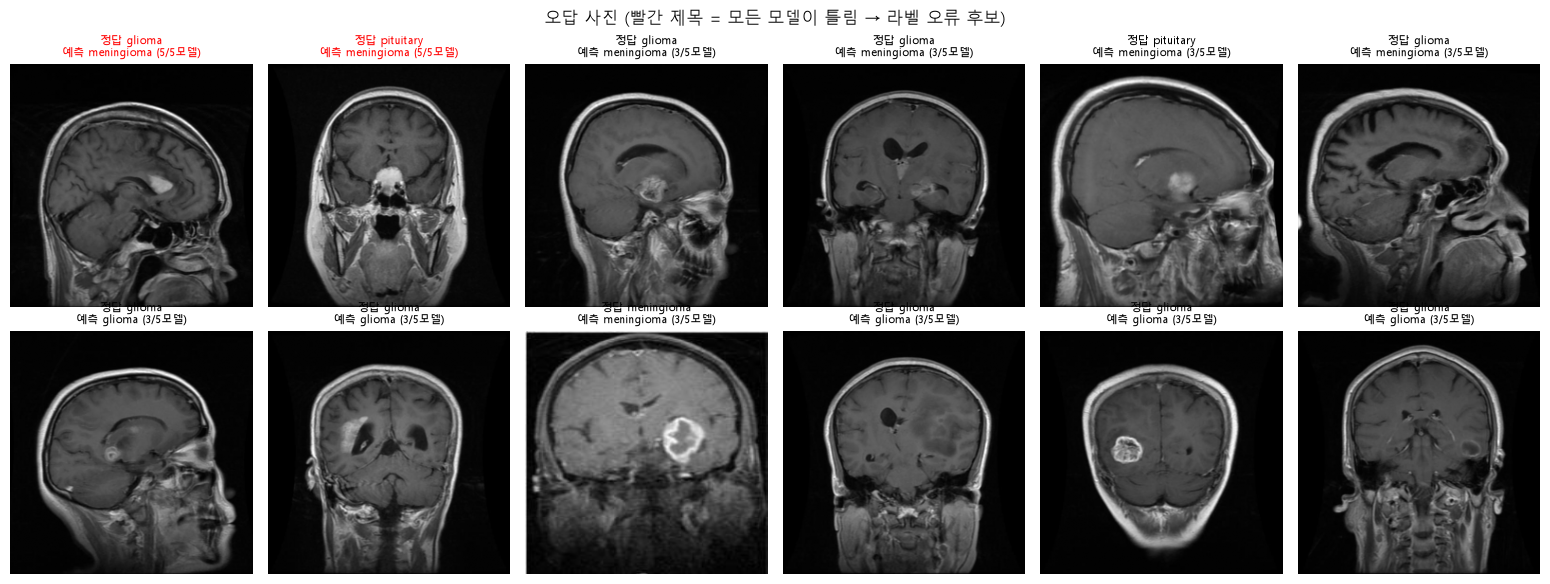

In [4]:
preds = np.stack([probs[t].argmax(1) for t in TAGS])          # 모델 수 × 882
n_wrong = (preds != y_test).sum(0)
err_idx = np.where(n_wrong > 0)[0]
err_idx = err_idx[np.argsort(-n_wrong[err_idx])]
print(f"한 모델이라도 틀린 사진: {len(err_idx)}장 / 모든 모델({len(TAGS)}개)이 틀린 사진: {(n_wrong == len(TAGS)).sum()}장\n")

tbl = pd.DataFrame({"test idx": err_idx, "정답": [CLASSES[y_test[i]] for i in err_idx],
                    "틀린 모델 수": n_wrong[err_idx],
                    **{t: [f"{CLASSES[preds[k, i]]} ({probs[t][i].max():.2f})" for i in err_idx] for k, t in enumerate(TAGS)},
                    "파일": [test_df.loc[i, "path"] for i in err_idx]})
display(tbl.head(20))

show = err_idx[:min(12, len(err_idx))]
if len(show):
    cols = 6; rws = int(np.ceil(len(show) / cols))
    fig, axes = plt.subplots(rws, cols, figsize=(cols * 2.6, rws * 3))
    for ax in np.atleast_1d(axes).ravel(): ax.axis("off")
    for ax, i in zip(np.atleast_1d(axes).ravel(), show):
        ax.imshow(cache["test"]["raw"][i, 0], cmap="gray")
        votes = pd.Series([CLASSES[p] for p in preds[:, i]]).value_counts()
        ax.set_title(f"정답 {CLASSES[y_test[i]]}\n예측 {votes.index[0]} ({votes.iloc[0]}/{len(TAGS)}모델)", fontsize=8,
                     color="red" if n_wrong[i] == len(TAGS) else "black")
    plt.suptitle("오답 사진 (빨간 제목 = 모든 모델이 틀림 → 라벨 오류 후보)"); plt.tight_layout(); plt.show()

## 4. 질문 3: 저해상도 지름길 테스트

> 🎯 **왜 하나요?**  
> 이미지를 **16×16, 8×8로 뭉개면** 종양은 거의 안 보이고 *전체적인 생김새*(단면 방향, 밝기 분포, 머리 크기·여백)만 남아요.  
> 이걸로 **딥러닝도 아닌 로지스틱 회귀**가 잘 맞힌다면? → 병변을 안 봐도 구분되는 **지름길이 데이터에 있다**는 증거예요.  
> 정형 데이터 경험 그대로: 픽셀 256개(16×16)를 변수로 쓰는 로지스틱 회귀예요.
>
> **원본(raw) vs 자른 버전(crop)**도 비교해요. 자르기로 여백·확대 차이를 없앴으니, crop에서 성능이 떨어지는 클래스는 *여백·구도가 지름길이었다*는 뜻이에요.

,acc,macro F1,recall_glioma,recall_meningioma,recall_notumor,recall_pituitary
설정,,,,,,
16×16 raw,0.807,0.804,0.783,0.673,0.918,0.884
16×16 crop,0.779,0.774,0.790,0.587,0.928,0.847
8×8 raw,0.766,0.763,0.746,0.561,0.845,0.898
8×8 crop,0.731,0.733,0.753,0.520,0.845,0.813
(참고) 무작위 찍기,0.250,NaN,NaN,NaN,NaN,NaN


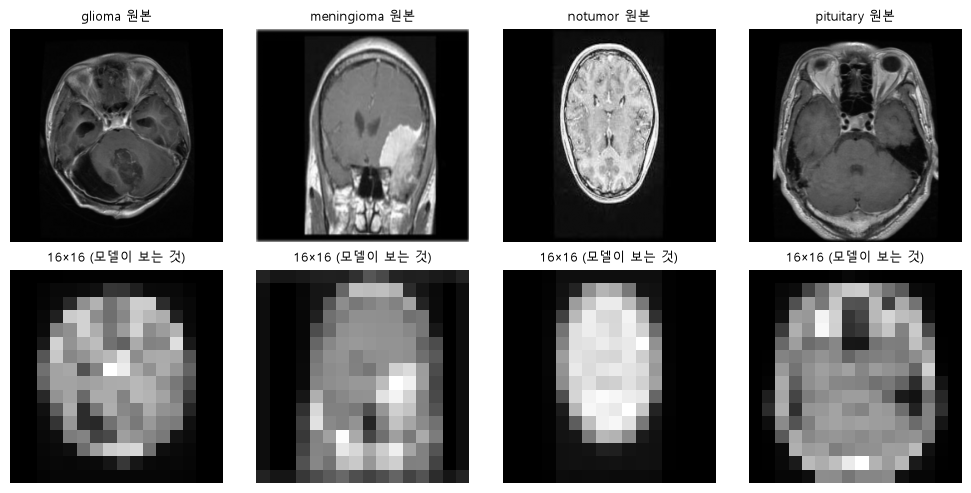

In [5]:
def lowres(imgs, s):
    return F.interpolate(imgs.float() / 255, size=(s, s), mode="area").flatten(1).numpy()

rows = []
for s in [16, 8]:
    for key in ["raw", "crop"]:
        Xtr, Xte = lowres(cache["train"][key], s), lowres(cache["test"][key], s)
        clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.5))
        clf.fit(Xtr, cache["train"]["y"].numpy())
        p = clf.predict(Xte); cm = confusion_matrix(y_test, p, labels=range(len(CLASSES)))
        rows.append({"설정": f"{s}×{s} {key}", "acc": (p == y_test).mean(), "macro F1": f1_score(y_test, p, average="macro"),
                     **{f"recall_{c}": cm[i, i] / cm[i].sum() for i, c in enumerate(CLASSES)}})
rows.append({"설정": "(참고) 무작위 찍기", "acc": 0.25})
display(pd.DataFrame(rows).set_index("설정").round(3))

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for k, cls in enumerate(CLASSES):
    i = np.where(y_test == CLS2IDX[cls])[0][0]
    axes[0, k].imshow(cache["test"]["raw"][i, 0], cmap="gray"); axes[0, k].set_title(f"{cls} 원본", fontsize=9)
    axes[1, k].imshow(lowres(cache["test"]["raw"][i:i + 1], 16).reshape(16, 16), cmap="gray"); axes[1, k].set_title("16×16 (모델이 보는 것)", fontsize=9)
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.show()

## 5. 질문 4: 테두리만 / 안쪽만 보여주기 실험

> 🎯 **왜 하나요?**  
> 노트북 3 Grad-CAM에서 notumor·pituitary가 **머리 테두리**를 봤어요. 그럼 **테두리만 남기고 뇌 안쪽을 까맣게 지우면** 어떻게 될까요?
> - 테두리만으로도 잘 맞힌다 → **테두리(두개골·두피) 지름길**이 있다
> - 거의 못 맞힌다(25~40%) → 테두리만으로는 판단 못 함 = 안쪽(병변 포함)을 실제로 씀
>
> 반대로 **안쪽만 남기고 테두리를 지운** 버전도 봐요. 이건 모델이 *처음 보는 형태*의 사진이라 성능이 좀 떨어지는 건 자연스러워요.  
> 핵심은 **클래스별로 어떤 클래스가 테두리만으로도 맞혀지는지**예요.

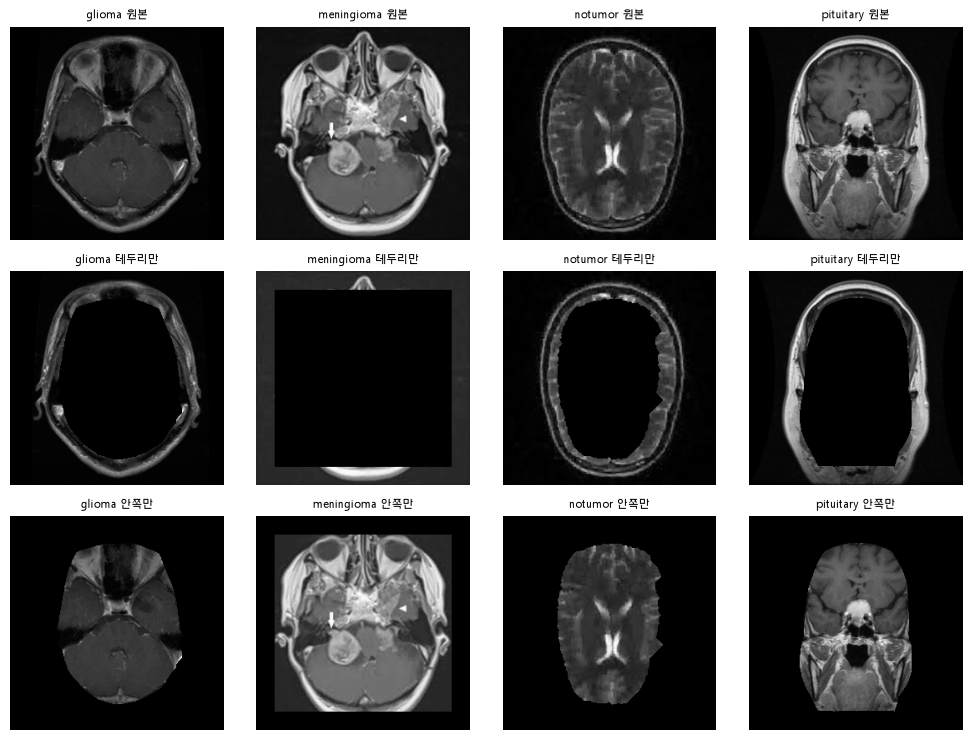

acc  glioma  meningioma  notumor  pituitary 가장 많이 예측한 클래스
모델 입력                                                               
E1 원본    0.977   0.963       0.974    1.000      0.986     pituitary
   테두리만  0.543   0.742       0.541    0.959      0.207       notumor
   안쪽만   0.802   0.654       0.893    0.969      0.833     pituitary
E2 원본    0.988   0.976       1.000    1.000      0.986     pituitary
   테두리만  0.305   0.342       0.372    0.979      0.000       notumor
   안쪽만   0.808   0.742       0.985    0.990      0.697    meningioma
E3 원본    0.972   0.956       0.949    1.000      0.993     pituitary
   테두리만  0.506   0.512       0.327    0.969      0.466       notumor
   안쪽만   0.621   0.969       0.837    0.588      0.139        glioma
E4 원본    0.995   0.997       0.995    1.000      0.993        glioma
   테두리만  0.553   0.386       0.791    0.979      0.422    meningioma
   안쪽만   0.773   0.739       0.918    0.990      0.639       notumor
E5 원본    0.988   0.976       1.000    1.000      0.986     pituitary
   테두리만  0.489   0.847       0.107    0.299      0.446        glioma
   안쪽만   0.946   0.932       0.990    0.979      0.918        glioma

In [6]:
ERODE = 22   # 테두리 두께(픽셀, 256 기준). 두개골+두피 정도

def split_border_inner(imgs):
    border, inner = imgs.clone(), imgs.clone()
    for i in range(len(imgs)):
        a = imgs[i, 0].numpy()
        m = head_mask(a); core = ndimage.binary_erosion(m, iterations=ERODE)
        b = border[i, 0].numpy(); b[core] = 0                        # 안쪽 지움 → 테두리만
        n = inner[i, 0].numpy(); n[~core] = 0                        # 테두리·배경 지움 → 안쪽만
    return border, inner

masked = {}
for key in ["raw", "crop"]:
    masked[key] = split_border_inner(cache["test"][key])

fig, axes = plt.subplots(3, 4, figsize=(10, 7.5))
for k, cls in enumerate(CLASSES):
    i = np.where(y_test == CLS2IDX[cls])[0][1]
    for r, (img, name) in enumerate([(cache["test"]["crop"], "원본"), (masked["crop"][0], "테두리만"), (masked["crop"][1], "안쪽만")]):
        axes[r, k].imshow(img[i, 0], cmap="gray"); axes[r, k].set_title(f"{cls} {name}", fontsize=8); axes[r, k].axis("off")
plt.tight_layout(); plt.show()

rows = []
for t in TAGS:
    key = "crop" if EXPERIMENTS[t]["crop"] else "raw"
    for name, imgs in [("원본", cache["test"][key]), ("테두리만", masked[key][0]), ("안쪽만", masked[key][1])]:
        p = predict(models[t], imgs).argmax(1); cm = confusion_matrix(y_test, p, labels=range(len(CLASSES)))
        rows.append({"모델": t, "입력": name, "acc": (p == y_test).mean(),
                     **{c: cm[i, i] / cm[i].sum() for i, c in enumerate(CLASSES)},
                     "가장 많이 예측한 클래스": CLASSES[np.bincount(p, minlength=4).argmax()]})
pd.DataFrame(rows).set_index(["모델", "입력"]).round(3)

## 6. 질문 5: Grad-CAM 정량화 — 뇌 안쪽을 보는 비율

> 🎯 **왜 하나요?**  
> 노트북 3·4에서 Grad-CAM을 **클래스당 3~4장** 눈으로만 봤어요. 이번엔 **test 882장 전체**에 대해  
> *"Grad-CAM 빨간 정도의 총합 중 몇 %가 뇌 안쪽(테두리 제외)에 있나"*를 계산해서 클래스별로 비교해요.  
> 비율이 높을수록 뇌 안쪽을 보고 판단한 거예요. **E1(원본) vs E2(자르기+증강)**, 그리고 **EfficientNet(E4)**도 비교해요.

In [7]:
from pytorch_grad_cam import GradCAM

def target_layer(tag, m):
    return m.layer4[-1] if "resnet" in EXPERIMENTS[tag]["model"] else m.bn2 if "efficientnet" in EXPERIMENTS[tag]["model"] else None

def inner_masks(imgs):
    out = []
    for i in range(len(imgs)):
        core = ndimage.binary_erosion(head_mask(imgs[i, 0].numpy()), iterations=ERODE)
        out.append(np.asarray(Image.fromarray(core.astype(np.uint8) * 255).resize((IMG, IMG), Image.NEAREST)) > 0)
    return np.stack(out)

CAM_BS = 16   # GPU 메모리가 부족하다는 에러가 나면 8로 줄이세요
rows = []
for t in [t for t in TAGS if target_layer(t, models[t]) is not None and t != "E3"]:
    key = "crop" if EXPERIMENTS[t]["crop"] else "raw"
    masks = inner_masks(cache["test"][key])
    ratios = []
    with GradCAM(model=models[t], target_layers=[target_layer(t, models[t])]) as cam:
        for x, _ in tqdm(DataLoader(CachedDS(cache["test"][key], cache["test"]["y"]), batch_size=CAM_BS), desc=f"{t} Grad-CAM"):
            ratios.append(cam(input_tensor=x.to(DEVICE), targets=None))
    heat = np.concatenate(ratios)
    r = (heat * masks).sum((1, 2)) / (heat.sum((1, 2)) + 1e-8)
    row = {"모델": f"{t} {EXPERIMENTS[t]['desc']}", "전체": r.mean()}
    row.update({c: r[y_test == i].mean() for i, c in enumerate(CLASSES)})
    row["(참고) 안쪽 면적 비율"] = masks.mean()
    rows.append(row)
cam_tbl = pd.DataFrame(rows).set_index("모델").round(3)
cam_tbl

E4 Grad-CAM: 100%|██████████| 56/56 [00:07<00:00,  7.47it/s]


,전체,glioma,meningioma,notumor,pituitary,(참고) 안쪽 면적 비율
모델,,,,,,
E1 ResNet50 원본,0.783,0.680,0.820,0.767,0.866,0.340
E2 ResNet50 자르기+증강,0.883,0.840,0.891,0.874,0.924,0.404
E4 EfficientNet-B0,0.702,0.741,0.772,0.437,0.703,0.404


**읽는 법**: 마지막 열 *"안쪽 면적 비율"*은 이미지에서 뇌 안쪽이 차지하는 면적이에요.  
Grad-CAM이 아무 데나 고르게 퍼져 있으면 안쪽 비율 ≈ 면적 비율이 돼요. **면적 비율보다 확실히 높아야** "안쪽에 집중했다"고 말할 수 있어요.

## 7. 추가: 확률을 믿을 수 있나? — 보정(calibration)

> 🎯 **왜 하나요?**  
> 노트북 2에서 "학습이 길어지면 모델이 **과하게 확신**한다"는 걸 봤어요. 임상에서 *"악성일 확률 95%"* 같은 숫자를 쓰려면,  
> 모델이 95%라고 말한 것들이 **실제로 95% 정도 맞아야** 해요.  
> **Reliability diagram**: 확신도 구간별로 실제 정답률을 그린 그래프. 대각선에 가까울수록 확률을 믿을 수 있어요.  
> **ECE**(Expected Calibration Error): 대각선에서 평균적으로 얼마나 벗어났나 (작을수록 좋음)

E1: ECE 0.0161 | 확신도 0.99 이상인 예측 88.2%, 그중 정답률 0.992
E2: ECE 0.0075 | 확신도 0.99 이상인 예측 90.7%, 그중 정답률 0.996
E3: ECE 0.0082 | 확신도 0.99 이상인 예측 70.0%, 그중 정답률 0.997
E4: ECE 0.0035 | 확신도 0.99 이상인 예측 96.9%, 그중 정답률 0.999
E5: ECE 0.0100 | 확신도 0.99 이상인 예측 93.7%, 그중 정답률 0.998


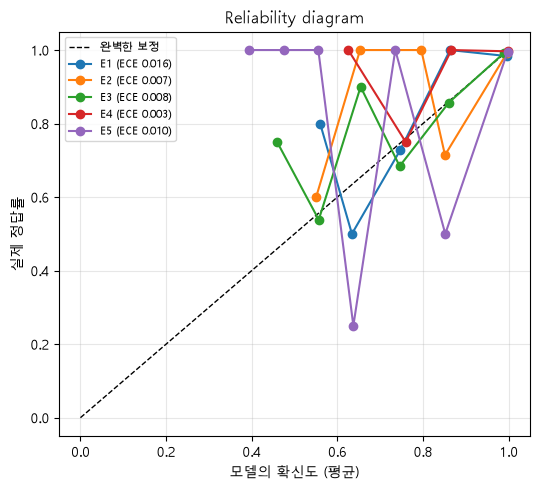

In [8]:
def ece_and_bins(p, y, n_bins=10):
    conf, pred = p.max(1), p.argmax(1)
    bins = np.linspace(0, 1, n_bins + 1); ece, xs, ys, ns = 0.0, [], [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() == 0: continue
        acc_b, conf_b = (pred[m] == y[m]).mean(), conf[m].mean()
        ece += m.mean() * abs(acc_b - conf_b); xs.append(conf_b); ys.append(acc_b); ns.append(m.sum())
    return ece, xs, ys, ns

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="완벽한 보정")
for t in TAGS:
    e, xs, ys, ns = ece_and_bins(probs[t], y_test)
    ax.plot(xs, ys, "o-", label=f"{t} (ECE {e:.3f})")
    conf = probs[t].max(1)
    print(f"{t}: ECE {e:.4f} | 확신도 0.99 이상인 예측 {np.mean(conf >= 0.99):.1%}, 그중 정답률 {(probs[t].argmax(1) == y_test)[conf >= 0.99].mean():.3f}")
ax.set_xlabel("모델의 확신도 (평균)"); ax.set_ylabel("실제 정답률"); ax.set_title("Reliability diagram"); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## ✍️ 정리 & 생각해볼 질문

1. **모델 간 차이**: E4가 정말 E2보다 낫다고 말할 수 있었나? 논문에 "E4가 가장 우수"라고 쓰려면 뭐가 더 필요할까?
2. **오답**: 모든 모델이 같은 답으로 틀린 사진이 있었나? 라벨 오류 후보로 보이나, 정말 어려운 사진인가?
3. **저해상도**: 16×16 로지스틱 회귀가 몇 %나 맞혔나? 어떤 클래스가 특히 잘 맞았나? raw → crop에서 떨어진 클래스는?
4. **테두리만**: 테두리만 보여줬을 때 잘 맞힌 클래스가 있었나? 그 클래스는 노트북 1 EDA에서 뭐라고 메모했던 클래스인가?
5. **Grad-CAM 비율**: 클래스별로 안쪽 비율이 낮은 클래스는? 면적 비율과 비교하면?
6. **보정**: 확신도 0.99 이상 예측은 실제로 몇 % 맞았나?
7. 종합하면, 이 모델의 99%를 **"뇌종양을 잘 구분한다"**고 말할 수 있을까? 어디까지 말할 수 있고, 어디부터는 못 할까?

**메모:**
- 
